In [11]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time

#Mes imports

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Ellipsoid_extinction_calc')
import nano_objects
importlib.reload(nano_objects)
from nano_objects import *


os.chdir(r'C:\Users\nberr\Documents\Code\python\Modules')
import Slider_plot
importlib.reload(Slider_plot)
from Slider_plot import *
import Slider_plot_v2
importlib.reload(Slider_plot_v2)
from Slider_plot_v2 import *

from matplotlib.widgets import Slider, Button


## Create a Nano_objecterial class for future implementation

get gold index data

Get data

In [12]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Data_refractive_index'
fname = 'Au - jhonson Christy.csv'
data = get_permittivity_tabulated_data(dir_root, fname)

Lda = data['lambda']*1e-9
Au_n = data['n']
Au_k = data['k']




interpolate data

In [13]:
n = sc.interpolate.interp1d(Lda, Au_n, kind='cubic', bounds_error=False, fill_value=1)
k = sc.interpolate.interp1d(Lda, Au_k, kind='cubic', bounds_error=False, fill_value=0)

Lambda = np.linspace(400e-9, 1200e-9, 1000)

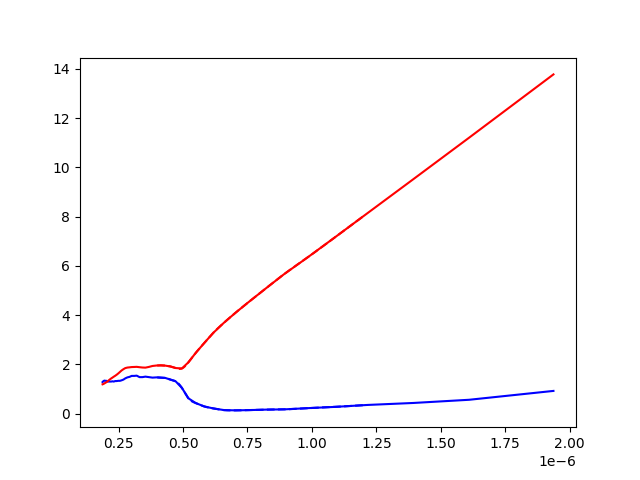

In [14]:
fig = plt.figure()

plt.plot(Lda, Au_n, color='b', label = 'n')
plt.plot(Lda, Au_k, color='r', label = 'k')

plt.plot(Lambda, n(Lambda), color='b', linestyle = '--')
plt.plot(Lambda, k(Lambda), color='r', linestyle = '--')

Create objects

In [15]:
dir_to_save = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Ellipsoid simulations\a=50, c=12'
save_data = 0

alpha = 1.42e-5 #in K-1 / thermal expansion coeff
dT=1
a_ini  = 50e-9
c_ini  = 12e-9
eps_ext_ini  = 1.9 *np.ones(np.size(Lambda))
deps_1_ini = 0
deps_2_ini  = 0

# Object in equilibrium

a=a_ini
c=c_ini
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = deps_2_ini
Gold_ellipse = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = 0, deps_2 = 0)
fname = 'a_{:.2f}_c_{:.2f}_eps_m_{}_deps1_{}_deps2_{}'.format(a*1e9, c*1e9, eps_ext[0], deps_1, deps_2)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse)


a=a_ini
c=c_ini
eps_ext = eps_ext_ini
deps_1 = 0.001
deps_2 = deps_2_ini
Gold_ellipse_with_deps_1 = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2)
fname = 'a_{:.2f}_c_{:.2f}_eps_m_{}_deps1_{}_deps2_{}'.format(a*1e9, c*1e9, eps_ext[0], deps_1, deps_2)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_deps_1)

a=a_ini
c=c_ini
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = 0.001
Gold_ellipse_with_deps_2 = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2)
fname = 'a_{:.2f}_c_{:.2f}_eps_m_{}_deps1_{}_deps2_{}'.format(a*1e9, c*1e9, eps_ext[0], deps_1, deps_2)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_deps_2)


a=a_ini + dT*alpha*a_ini
c=c_ini + dT*alpha*c_ini
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = deps_2_ini
Gold_ellipse_with_dilatation = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2)
fname = 'a_{:.5f}_c_{:.5f}_eps_m_{}_deps1_{}_deps2_{}_dilatation_dT_{}_K'.format(a*1e9, c*1e9, eps_ext[0], deps_1, deps_2, dT)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_dilatation)




## élongation horizontale, contraction verticale, avec volume conservé :

Volume ellispoide : $V = \frac{4}{3} \pi abc$

Elongation horizontale : a -> a+ $\alpha \cdot dT \cdot a$

On pose c = c - $\eta \cdot c$

La conservation de volume impose $\eta = 1 - \frac{1}{1+(\alpha \cdot dT)^2}$

In [16]:
a=a_ini + dT*alpha*a_ini
c= c_ini - c_ini * (1 - 1 /(1 + (alpha*dT))**2)
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = deps_2_ini
Gold_ellipse_with_acoustic_mode = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2)
fname = 'a_{:.5f}_c_{:.5f}_eps_m_{}_deps1_{}_deps2_{}_contraction_dT_{}_K'.format(a*1e9, c*1e9, eps_ext[0], deps_1, deps_2, dT)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_acoustic_mode)


## Try to make some parameter vary

In [17]:
slider_bool = 1

In [18]:
def plot_LSPR(arg_cte, arg_var, labels=False) :
    a = arg_var[0]
    c = arg_var[1]
    eps_ext = arg_var[2]


    mat = arg_cte[0]

    #vary matter
    mat.a = a
    mat.c = c
    mat.eps_ext = eps_ext
    mat.update()

    sigma_abs, sigma_scat, sigma_ext = mat.sigma_abs, mat.sigma_scat, mat.sigma_ext


    Labels = []
    
    if labels :
        Labels.append(Label_info(label = 'Sigma_abs', linestyle = '-', color = 'black'))
        Labels.append(Label_info(label = 'Sigma_ext', linestyle = '-', color = 'red'))

    return(mat.wl*1e9, [sigma_abs*1e15, sigma_ext*1e15], Labels)






def plot_LSPR_shift(arg_cte, arg_var, labels=False) :
    delta_eps1 = arg_var[0]
    delta_eps2 = arg_var[1]
    delta_eps_ext = arg_var[2]


    mat = arg_cte[0]

    #vary matter
    mat.eps_1 += delta_eps1
    mat.eps_2 += delta_eps2
    mat.eps_ext += delta_eps_ext
    mat.update()

    sigma_abs, sigma_scat, sigma_ext = mat.sigma_abs, mat.sigma_scat, mat.sigma_ext

    #reset matter
    mat.eps_1 -= delta_eps1
    mat.eps_2 -= delta_eps2
    mat.eps_ext -= delta_eps_ext
    mat.update()

    Labels = []
    if labels :
        Labels.append(Label_info(label = 'Sigma_abs', linestyle = 'dashed', color = 'blue'))
        Labels.append(Label_info(label = 'Sigma_scat', linestyle = 'dashed', color = 'red'))
        Labels.append(Label_info(label = 'Sigma_ext', linestyle = '-', color = 'black'))

    return(mat.wl*1e9, [sigma_abs*1e16, sigma_scat*1e16, sigma_ext*1e16], Labels)


def plot_LSPR_delta(arg_cte, arg_var, labels=False) :

    delta_eps1 = arg_var[0]
    delta_eps2 = arg_var[1]
    delta_eps_ext = arg_var[2]


    mat = arg_cte[0]


    sigma_abs_i, sigma_scat_i, sigma_ext_i = mat.sigma_abs, mat.sigma_scat, mat.sigma_ext

    #vary matter
    mat.eps_1 += delta_eps1
    mat.eps_2 += delta_eps2
    mat.eps_ext += delta_eps_ext
    mat.update()

    sigma_abs_f, sigma_scat_f, sigma_ext_f = mat.sigma_abs, mat.sigma_scat, mat.sigma_ext
    
    # delta_abs = sigma_abs_f - sigma_abs_i
    # delta_scat =  sigma_scat_f - sigma_scat_i
    # delta_ext =  sigma_ext_f - sigma_ext_i

    delta_abs = np.abs(sigma_abs_f - sigma_abs_i)
    delta_scat =  np.abs(sigma_scat_f - sigma_scat_i)
    delta_ext =  np.abs(sigma_ext_f - sigma_ext_i)

    #reset matter
    mat.eps_1 -= delta_eps1
    mat.eps_2 -= delta_eps2
    mat.eps_ext -= delta_eps_ext
    mat.update()

    Labels = []
    if labels :
        Labels.append(Label_info(label = 'Delta_abs', linestyle = 'dashed', color = 'blue'))
        Labels.append(Label_info(label = 'Delta_scat', linestyle = 'dashed', color = 'red'))
        Labels.append(Label_info(label = 'Delta_ext', linestyle = '-', color = 'black'))

    return(mat.wl*1e9, [delta_abs*1e16, delta_scat*1e16, delta_ext*1e16], Labels)


Figure(900x400)
Axes(0.125,0.11;0.775x0.77)
['a', 'c', '$\\varepsilon_m$']


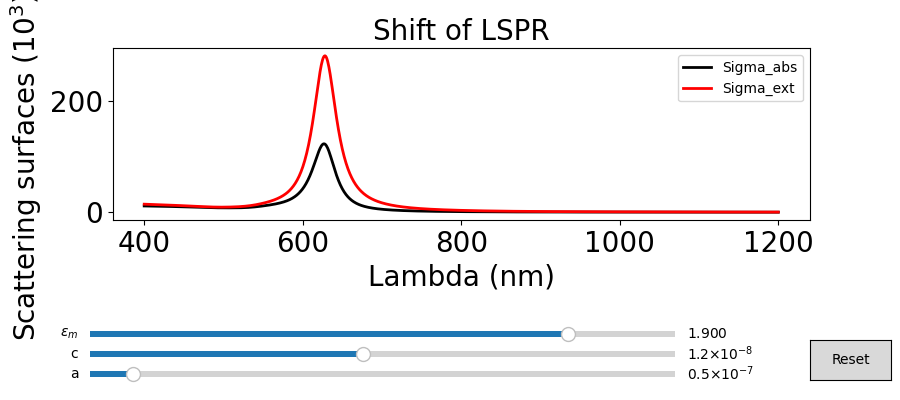

In [19]:
LSPR_plot = Param_slider()
LSPR_plot.add_param(r'a', 50e-9, 30e-9, 300e-9, label_power =9)
LSPR_plot.add_param(r'c', 12e-9, 5e-9, 20e-9, label_power =9)
LSPR_plot.add_param(r'$\varepsilon_m$', 1.9, 1, 1.45**2, label_power=0)

LSPR_plot.plot(plot_LSPR, [Gold_ellipse], titre='Shift of LSPR', xtitle='Lambda (nm)', ytitle=r'Scattering surfaces (10$^3$) nm$^2$')